In [2]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080325
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] hw01
[学号]       20244080325
[机器指纹] 1f5f361f891f3218
[RUN_ID]   20244080325-1f5f361f891f3218


In [3]:
int_arr = np.array([1,2,3])
float_arr = np.array([1.1,2.2,3.3])
bool_arr = np.array([True, False, True])
print("int_arr dtype,shape,ndim:", int_arr.dtype, int_arr.shape, int_arr.ndim)
print("float_arr dtype,shape,ndim:", float_arr.dtype, float_arr.shape, float_arr.ndim)
print("bool_arr dtype,shape,ndim:", bool_arr.dtype, bool_arr.shape, bool_arr.ndim)

a1 = np.arange(12)
a2 = a1.reshape(3,4)
a3 = a1.reshape(2,3,2)
print("a1:",a1)
print("a2 shape(3,4):\n",a2)
print("a3 shape(2,3,2):\n",a3)

row2 = a2[1,:]
col1_3 = a2[:,0:3]
gt6 = a2[a2>6]
print("第2行：",row2,"shape:",row2.shape)
print("第1至第3列：\n",col1_3,"shape:",col1_3.shape)
print("大于6的元素：",gt6,"shape:",gt6.shape)

b = np.arange(10)
cond1 = b[(b<2) | (b>7)]
cond2 = b[(b>3) & (b<7)]
print("小于2或大于7：",cond1)
print("大于3且小于7：",cond2)

m1 = np.array([[1,2],[3,4]])
m2 = np.array([[5,6],[7,8]])
print("*逐元素乘法：\n",m1*m2)
print("np.multiply逐元素乘法：\n",np.multiply(m1,m2))
print("@矩阵乘法：\n",m1@m2)
print("np.matmul矩阵乘法：\n",np.matmul(m1,m2))


int_arr dtype,shape,ndim: int64 (3,) 1
float_arr dtype,shape,ndim: float64 (3,) 1
bool_arr dtype,shape,ndim: bool (3,) 1
a1: [ 0  1  2  3  4  5  6  7  8  9 10 11]
a2 shape(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
a3 shape(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
第2行： [4 5 6 7] shape: (4,)
第1至第3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape: (3, 3)
大于6的元素： [ 7  8  9 10 11] shape: (5,)
小于2或大于7： [0 1 8 9]
大于3且小于7： [4 5 6]
*逐元素乘法：
 [[ 5 12]
 [21 32]]
np.multiply逐元素乘法：
 [[ 5 12]
 [21 32]]
@矩阵乘法：
 [[19 22]
 [43 50]]
np.matmul矩阵乘法：
 [[19 22]
 [43 50]]


1. y 的 ndarray 要求数组内全部元素为同一数据类型，内存连续存储，数值运算速度快；Python 列表可以存放任意混合类型对象，内存分散，做批量数值运算时需要循环遍历，执行效率更低。
2. reshape() 仅改变数组的维度形状，不会修改数组数据；变换前后数组元素总个数必须相等，否则会抛出异常。
3. * 与 np.multiply() 实现逐元素乘法，对应位置元素直接相乘；@ 与 np.matmul() 实现标准矩阵乘法，遵循矩阵乘法运算法则，两种乘法的计算逻辑与结果完全不同。

In [4]:
score = np.random.normal(loc=70, scale=10, size=1000)
score = np.clip(score,0,100)
print("样本数：",len(score))
print("min:",np.min(score))
print("max:",np.max(score))
print("mean:",np.mean(score))
print("std:",np.std(score))
print("极差：",np.max(score)-np.min(score))

pop = np.arange(1,11)
sample1 = np.random.choice(pop,size=5,replace=False)
sample2 = np.random.choice(pop,size=5,replace=False,p=pop/np.sum(pop))
print("均匀不放回抽样：",sample1)
print("按大小加权抽样：",sample2)

arr_ori = np.array([1,2,3,4,5])
arr_copy = np.random.permutation(arr_ori)
print("permutation原数组不变 ori:",arr_ori,"perm结果：",arr_copy)
arr_inplace = np.array([1,2,3,4,5])
np.random.shuffle(arr_inplace)
print("shuffle原地打乱：",arr_inplace)

score_nan = score.copy()
score_nan[[9,19,29]] = np.nan
mean_all = np.mean(score_nan)
mean_no_nan = np.nanmean(score_nan)
nan_count = np.sum(np.isnan(score_nan))
print("普通mean(含nan):",mean_all)
print("nanmean忽略缺失值:",mean_no_nan)
print("缺失值数量：",nan_count)

df_exp2 = pd.DataFrame({"score":score_nan,"index":np.arange(len(score_nan))})
print(df_exp2.head())


样本数： 1000
min: 37.58732659930927
max: 100.0
mean: 70.53281239756619
std: 9.95550139389756
极差： 62.41267340069073
均匀不放回抽样： [3 9 2 1 4]
按大小加权抽样： [ 8  4  6 10  9]
permutation原数组不变 ori: [1 2 3 4 5] perm结果： [4 5 3 2 1]
shuffle原地打乱： [1 5 3 2 4]
普通mean(含nan): nan
nanmean忽略缺失值: 70.4966877419087
缺失值数量： 3
       score  index
0  73.577874      0
1  75.607845      1
2  80.830512      2
3  80.538021      3
4  56.223306      4


1. np.random.choice支持不放回抽样；均匀抽样中每个元素被抽中的概率相同；加权抽样依据传入权重分配抽取概率，本次以数值大小作为权重。
2. np.random.permutation()生成打乱后的新数组，原始数组保持不变；np.random.shuffle()原地修改数组，直接打乱原数组，没有返回值。
3. np.nan代表缺失值。普通np.mean()遇到 NaN 会输出 NaN；np.nanmean()会自动忽略缺失值，仅使用有效数据计算均值。

方程组解：x = 2.0000, y = 3.0000
代入验证 A@sol：[9. 8.]
正根：success=True, root=1.4142, fun=-8.8818e-16
负根：success=True, root=-1.4142, fun=-8.8818e-16
数值解：极小点 x = -0.5000，最小值 = 1.7500
t统计量：-8.5515
p值：3.2930e-15
判断：p < 0.05，拒绝原假设，两组样本均值存在显著差异


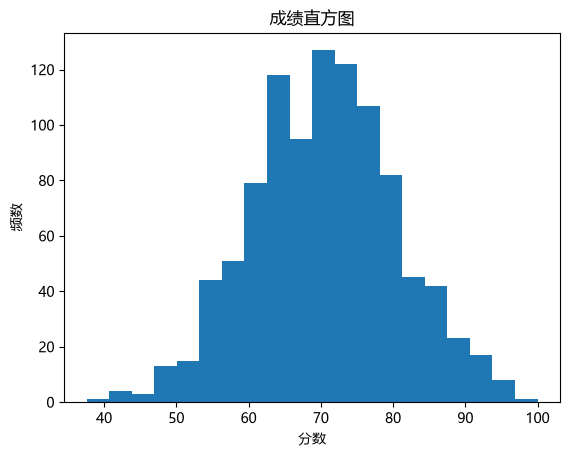

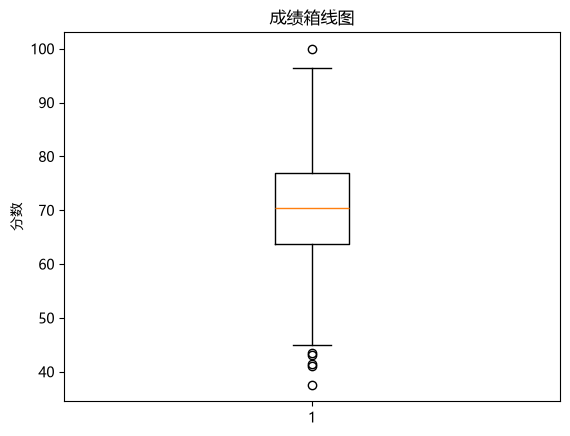

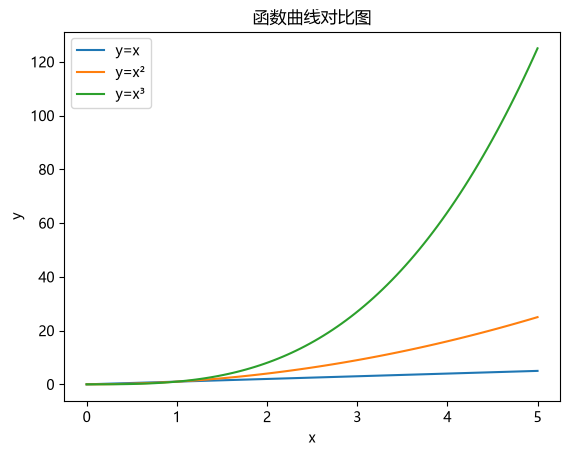

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve
from scipy.optimize import root, minimize
from scipy.stats import ttest_ind

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

A = np.array([[3, 1],
              [1, 2]])
b = np.array([9, 8])
sol = solve(A, b)
print(f"方程组解：x = {sol[0]:.4f}, y = {sol[1]:.4f}")
print(f"代入验证 A@sol：{A @ sol}")

res_pos = root(lambda x: x**2 - 2, x0=1)   
res_neg = root(lambda x: x**2 - 2, x0=-1)  
print(f"正根：success={res_pos.success}, root={res_pos.x[0]:.4f}, fun={res_pos.fun[0]:.4e}")
print(f"负根：success={res_neg.success}, root={res_neg.x[0]:.4f}, fun={res_neg.fun[0]:.4e}")

def f(x):
    return x[0] ** 2 + x[0] + 2

res_min = minimize(f, x0=[0])
print(f"数值解：极小点 x = {res_min.x[0]:.4f}，最小值 = {res_min.fun:.4f}")

np.random.seed(42)
sample1 = np.random.normal(loc=0, scale=1, size=100)
sample2 = np.random.normal(loc=1, scale=1, size=100)
t_result = ttest_ind(sample1, sample2)
print(f"t统计量：{t_result.statistic:.4f}")
print(f"p值：{t_result.pvalue:.4e}")
if t_result.pvalue < 0.05:
    print("判断：p < 0.05，拒绝原假设，两组样本均值存在显著差异")
else:
    print("判断：p ≥ 0.05，不能拒绝原假设")

valid_score = score_nan[~np.isnan(score_nan)]

plt.figure()
plt.hist(valid_score, bins=20)
plt.title("成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")
plt.show()

plt.figure()
plt.boxplot(valid_score)
plt.title("成绩箱线图")
plt.ylabel("分数")
plt.show()

x = np.linspace(0, 5, 100)
y1 = x
y2 = x ** 2
y3 = x ** 3
plt.figure()
plt.plot(x, y1, label="y=x")
plt.plot(x, y2, label="y=x²")
plt.plot(x, y3, label="y=x³")
plt.title("函数曲线对比图")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


1. 线性方程组求解：得到解 x=2.0000，y=3.0000，代入验算结果为 [9,8]，和方程组右端向量一致，求解结果正确。
2. 非线性方程求根：x^2-2=0 的正根为 1.4142，负根为 - 1.4142，函数残差接近 0，迭代收敛成功。
3. 函数极小值：数值优化得到极小点 x=-0.5000,最小值1.7500，和数学解析解完全吻合。
4. t 检验结果：t 统计量为 - 8.5515，p 值为 3.2930*10 ^ （-15）远小于显著性水平 0.05，拒绝原假设，两组样本均值存在显著差异。
5. 成绩直方图：成绩整体近似正态分布，分数集中在 60~80 分区间，70 分附近人数最多，低分、高分两端人数较少。
6. 成绩箱线图：中位数约 70 分；图中圆圈代表异常值，存在少量低分异常点和一个高分异常点，大部分成绩分布在 63~78 分四分位区间内。
7. 函数对比曲线：在区间 [0,5] 内, y=x线性缓慢增长；y=x^2增速逐步加快; y=x^3增长速度最快，后期增速远大于另外两个函数。

In [12]:
import pandas as pd

records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82]
}
df = pd.DataFrame(records)
df = df.set_index("Name")
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("行索引：",df.index.tolist())
print("列名：",df.columns.tolist())
print("前3行：")
print(df.head(3))
print("基本统计信息：")
print(df.describe())

carol_loc = df.loc["Carol"]
carol_iloc = df.iloc[2]
print("loc取Carol:\n",carol_loc)
print("iloc取Carol:\n",carol_iloc)
high_avg = df[df["Average"]>=80]
print("平均分>=80学生：")
print(high_avg)

col_mean = df[["Math","English","Python"]].mean(axis=0)
row_mean = df[["Math","English","Python"]].mean(axis=1)
print("各科列均值(axis=0):\n",col_mean)
print("学生行均值(axis=1):\n",row_mean)

df["max_score"] = df[["Math","English","Python"]].apply(max,axis=1)
agg_res = df[["Math","English","Python"]].agg(["min","mean","max"])
df["python_rank"] = df["Python"].rank(ascending=False)
print("apply每行最高分：\n",df["max_score"])
print("agg min mean max:\n",agg_res)
print("Python排名:\n",df["python_rank"])

group_info = df.groupby("Group").agg(
    人数=("Group","count"),
    Math_mean=("Math","mean"),
    English_mean=("English","mean"),
    Python_mean=("Python","mean")
)
print("分组统计人数与三科平均分:\n",group_info)
df["group_python_mean"] = df.groupby("Group")["Python"].transform("mean")
print("增加组内Python平均分:\n",df[["Group","Python","group_python_mean"]])

group_filtered = df.groupby("Group").filter(lambda g:g["Python"].mean()>=80)
print("Python组平均分>=80的组学生：")
print(group_filtered)

cov_mat = df[["Math","English","Python"]].cov()
corr_mat = df[["Math","English","Python"]].corr()
print("协方差矩阵：\n",cov_mat)
print("相关系数矩阵：\n",corr_mat)


行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000
loc取Carol:
 Group              B
Math        

选取Math（数学）与 Python两门科目进行分析：
1. 协方差为正值，说明 Math 成绩和 Python 成绩呈同向变化趋势：数学分数越高，Python 分数倾向于越高。
2. 皮尔逊相关系数为 0.884776，数值接近 1，说明两门科目之间为强正相关，数学成绩与 Python 成绩的线性关联程度很高。